<div style="font-family:Times New Roman;font-size:14pt;color:black"><b>Лабораторна робота 6</b><br>Запобігання перенавчанню. L1 і L2 регуляризація<br>Виконав Шиндир Олексій<br>4 курс, 10 група</div>

<a href="https://colab.research.google.com/github/raysewww-lang/mashynne-navchannia/blob/main/%D0%A8%D0%B8%D0%BD%D0%B4%D0%B8%D1%80_%D0%BF%D1%80_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Відкрити в Colab"/></a>

In [1]:
# Підготовка бібліотек і даних. Дані автоматично завантажуються з GitHub; резервний спосіб — data.zip.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display
from sklearn.model_selection import train_test_split, GridSearchCV, KFold, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score, classification_report, ConfusionMatrixDisplay
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
np.random.seed(25)
plt.rcParams.update({'font.family':'serif','font.serif':['Times New Roman','DejaVu Serif'],'font.size':14,'figure.figsize':(9,5)})
pd.set_option('display.max_columns',40)

def data_path(name):
    for folder in [Path('data'),Path('.'),Path('/content/data'),Path('/content')]:
        p=folder/name
        if p.exists():
            return p
    import zipfile, io
    from urllib.request import urlopen
    try:
        url='https://raw.githubusercontent.com/raysewww-lang/mashynne-navchannia/main/data.zip'
        with urlopen(url, timeout=60) as response:
            content=response.read()
        Path('data').mkdir(exist_ok=True)
        with zipfile.ZipFile(io.BytesIO(content)) as z:
            for member in z.namelist():
                if not member.endswith('/'):
                    (Path('data')/Path(member).name).write_bytes(z.read(member))
        if (Path('data')/name).exists():
            return Path('data')/name
    except Exception as error:
        print('Автоматичне завантаження недоступне:',error)
    from google.colab import files
    import zipfile, io
    print('Завантажте data.zip або файл',name)
    uploaded=files.upload()
    Path('data').mkdir(exist_ok=True)
    for fname,content in uploaded.items():
        if fname.endswith('.zip'):
            with zipfile.ZipFile(io.BytesIO(content)) as z:
                for member in z.namelist():
                    if not member.endswith('/'):
                        (Path('data')/Path(member).name).write_bytes(z.read(member))
        else:
            (Path('data')/Path(fname).name).write_bytes(content)
    p=Path('data')/name
    if not p.exists():
        raise FileNotFoundError(name)
    return p

In [2]:
# Завдання 1. Пункти 1–3: дані, поділ, базова регресія, аналіз перенавчання. Використано надані ціни житла.
df=pd.read_csv(data_path('house_price_regression_dataset.csv'))

display(df.head()); print('Розмір:',df.shape);display(df.dtypes)
display(df.isna().sum());print('Дублікати:',df.duplicated().sum())
df=df.drop_duplicates().copy()
display(df.describe())

X=df.drop(columns='House_Price');y=df.House_Price
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=25)
base=Pipeline([('fill',SimpleImputer()),('scale',StandardScaler()),('model',LinearRegression())])
base.fit(X_train,y_train)
print('Базова модель: train MSE',mean_squared_error(y_train,base.predict(X_train)),'test MSE',mean_squared_error(y_test,base.predict(X_test)))

,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
0,1360,2,1,1981,0.599637,0,5,2.623829e+05
1,4272,3,3,2016,4.753014,1,6,9.852609e+05
2,3592,1,2,2016,3.634823,0,9,7.779774e+05
3,966,1,2,1977,2.730667,1,8,2.296989e+05
4,4926,2,1,1993,4.699073,0,8,1.041741e+06


Розмір: (1000, 8)


Square_Footage            int64
Num_Bedrooms              int64
Num_Bathrooms             int64
Year_Built                int64
Lot_Size                float64
Garage_Size               int64
Neighborhood_Quality      int64
House_Price             float64
dtype: object

Square_Footage          0
Num_Bedrooms            0
Num_Bathrooms           0
Year_Built              0
Lot_Size                0
Garage_Size             0
Neighborhood_Quality    0
House_Price             0
dtype: int64

Дублікати: 0


,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1.000000e+03
mean,2815.422000,2.990000,1.973000,1986.550000,2.778087,1.022000,5.615000,6.188610e+05
std,1255.514921,1.427564,0.820332,20.632916,1.297903,0.814973,2.887059,2.535681e+05
min,503.000000,1.000000,1.000000,1950.000000,0.506058,0.000000,1.000000,1.116269e+05
25%,1749.500000,2.000000,1.000000,1969.000000,1.665946,0.000000,3.000000,4.016482e+05
50%,2862.500000,3.000000,2.000000,1986.000000,2.809740,1.000000,6.000000,6.282673e+05
75%,3849.500000,4.000000,3.000000,2004.250000,3.923317,2.000000,8.000000,8.271413e+05
max,4999.000000,5.000000,3.000000,2022.000000,4.989303,2.000000,10.000000,1.108237e+06


Базова модель: train MSE 92572933.00671586 test MSE 107226465.49652694


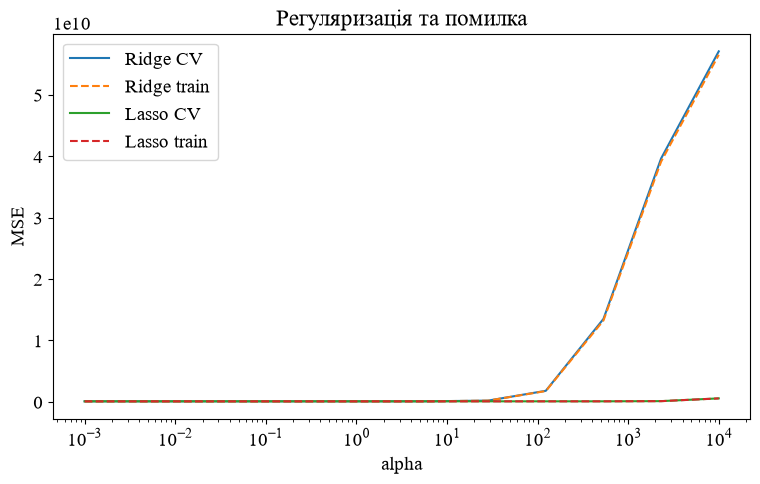

,Модель,alpha,Train MSE,Test MSE,Test R2,CV MSE
0,Лінійна,NaN,9.257293e+07,1.072265e+08,0.998336,NaN
1,Ridge,0.351119,9.258541e+07,1.074790e+08,0.998332,9.571259e+07
2,Lasso,28.480359,9.257863e+07,1.074188e+08,0.998333,9.570973e+07


Розрив Test MSE - Train MSE:


Модель
Лінійна    1.465353e+07
Ridge      1.489364e+07
Lasso      1.484016e+07
dtype: float64

Регуляризація не обов’язково покращує тест: при простій лінійній залежності сильне alpha спричиняє недонавчання. Порівняння наведено в таблиці.


In [3]:
# Завдання 1. Пункти 4–6: L1 та L2, різні alpha, крос-валідація, оцінка, графіки і висновки.
alphas=np.logspace(-3,4,12)
cv=KFold(n_splits=5,shuffle=True,random_state=25)
rows=[['Лінійна',np.nan,mean_squared_error(y_train,base.predict(X_train)),mean_squared_error(y_test,base.predict(X_test)),r2_score(y_test,base.predict(X_test)),np.nan]]
fitted={'Лінійна':base}
for name,model in [('Ridge',Ridge()),('Lasso',Lasso(max_iter=20000))]:
    pipe=Pipeline([('fill',SimpleImputer()),('scale',StandardScaler()),('model',model)])
    grid=GridSearchCV(pipe,{'model__alpha':alphas},cv=cv,scoring='neg_mean_squared_error',return_train_score=True)
    grid.fit(X_train,y_train);fitted[name]=grid
    rows.append([name,grid.best_params_['model__alpha'],mean_squared_error(y_train,grid.predict(X_train)),mean_squared_error(y_test,grid.predict(X_test)),r2_score(y_test,grid.predict(X_test)),-grid.best_score_])
    plt.semilogx(alphas,-grid.cv_results_['mean_test_score'],label=name+' CV')
    plt.semilogx(alphas,-grid.cv_results_['mean_train_score'],'--',label=name+' train')
plt.xlabel('alpha');plt.ylabel('MSE');plt.legend();plt.title('Регуляризація та помилка');plt.show()
results=pd.DataFrame(rows,columns=['Модель','alpha','Train MSE','Test MSE','Test R2','CV MSE']);display(results)
print('Розрив Test MSE - Train MSE:');display(results.set_index('Модель')['Test MSE']-results.set_index('Модель')['Train MSE'])
print('Регуляризація не обов’язково покращує тест: при простій лінійній залежності сильне alpha спричиняє недонавчання. Порівняння наведено в таблиці.')

In [4]:
# Висновок. Завдання 1. Побудовано базову модель, Ridge та Lasso. Alpha обрано за п’ятиблоковою крос-валідацією. Порівняння навчальної і тестової помилки показує величину розриву узагальнення; графік демонструє вплив надмірної регуляризації.

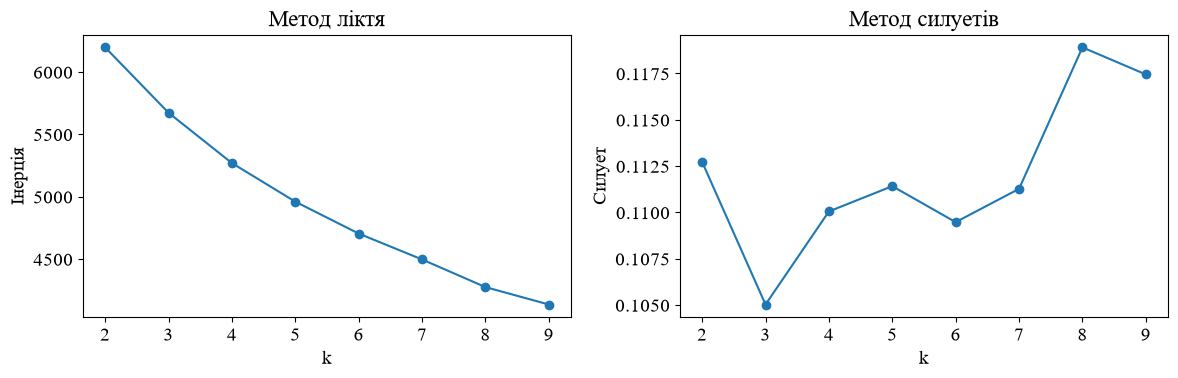

Лікоть за відстанню від хорди: 5 ; максимальний силует: 8


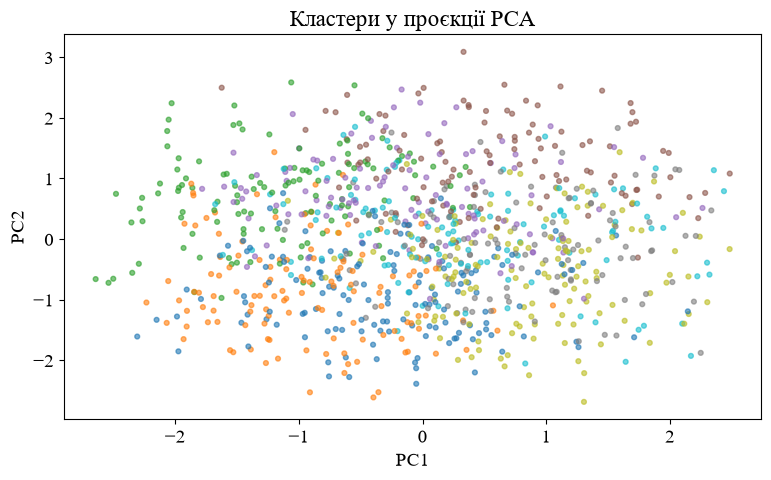

Висновок: обрано k = 8 за максимальним силуетом 0.119 . Лікоть пропонує 5 . Проєкція PCA спрощує багатовимірну структуру.


In [5]:
# Завдання 2. Кластеризація житла. Методи ліктя та силуетів, вибір кількості кластерів і візуалізація.
cluster_X=df.drop(columns='House_Price')
cluster_X=StandardScaler().fit_transform(SimpleImputer().fit_transform(cluster_X))
ks=list(range(2,10));inertia=[];sil=[]
for k in ks:
    km=KMeans(n_clusters=k,n_init=10,random_state=25)
    labels=km.fit_predict(cluster_X)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(cluster_X,labels,sample_size=min(len(cluster_X),2000),random_state=25))
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].plot(ks,inertia,'o-');axes[0].set(xlabel='k',ylabel='Інерція',title='Метод ліктя')
axes[1].plot(ks,sil,'o-');axes[1].set(xlabel='k',ylabel='Силует',title='Метод силуетів');plt.tight_layout();plt.show()
points=np.column_stack([ks,inertia]).astype(float)
points=(points-points.min(axis=0))/(points.max(axis=0)-points.min(axis=0))
line=points[-1]-points[0]
distance=np.abs(line[0]*(points[:,1]-points[0,1])-line[1]*(points[:,0]-points[0,0]))/np.linalg.norm(line)
elbow_k=ks[int(distance.argmax())]
best_k=ks[int(np.argmax(sil))]
print('Лікоть за відстанню від хорди:',elbow_k,'; максимальний силует:',best_k)
km=KMeans(n_clusters=best_k,n_init=10,random_state=25)
labels=km.fit_predict(cluster_X)
xy=PCA(n_components=2).fit_transform(cluster_X)
plt.scatter(xy[:,0],xy[:,1],c=labels,cmap='tab10',s=12,alpha=0.6)
plt.xlabel('PC1');plt.ylabel('PC2');plt.title('Кластери у проєкції PCA');plt.show()
print('Висновок: обрано k =',best_k,'за максимальним силуетом',round(max(sil),3),'. Лікоть пропонує',elbow_k,'. Проєкція PCA спрощує багатовимірну структуру.')

In [6]:
# Висновок. Завдання 2. Для стандартизованих характеристик житла застосовано KMeans. Кількість кластерів оцінено ліктем і силуетом, результат показано у двовимірній PCA-проєкції.